# Xenium mouse kidney - ShamR

In [1]:
from pathlib import Path
import ssaft as cms

ROOT       = "/bce/groups/pnucolab/analysis/l202255179/UNNAMED"
XENIUM_DIR = f"{ROOT}/cellman_paper/data/xenium/ShamR-output-XETG00063__0005295__Region_6__20230717__191520"

STORE_ROOT = f"{ROOT}/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR"
ZARR       = f"{STORE_ROOT}/spatialdata.zarr"
CROPS      = f"{STORE_ROOT}/spatialdata_crops"
STORE      = f"{STORE_ROOT}/cellman_spatial"         
SCRIPTS    = f"{ROOT}/SSAF-T/ssaft/scripts"

DEVICE     = "cuda:1"            
NCORES     = 30

Path(STORE_ROOT).mkdir(parents=True, exist_ok=True)
print("ssaft", cms.__version__, "| store:", STORE) 

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ssaft 0.1.0 | store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/ssaft


## Step 1 — Load the Xenium sample into SpatialData

In [4]:
import spatialdata as sd
import spatialdata_io

if Path(ZARR).exists():
    sdata = sd.read_zarr(ZARR)
    print("loaded existing", ZARR)
else:
    sdata = spatialdata_io.xenium(XENIUM_DIR)
    sdata.write(ZARR)
    print("wrote", ZARR)
sdata

/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the

wrote /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
│     └── 'morphology_mip': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
│     └── 'nucleus_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (84419, 300)
with coordinate systems:
    ▸ 'global'

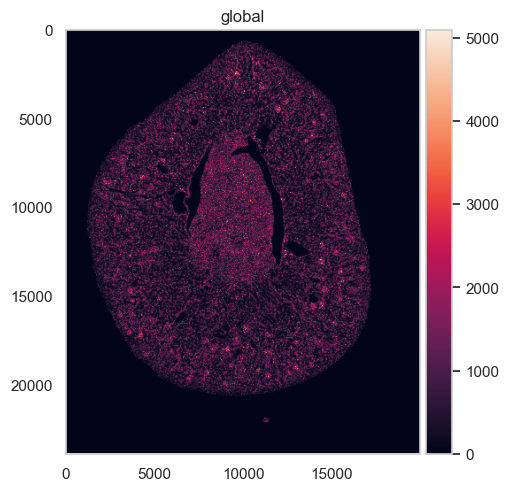

In [5]:
import spatialdata_plot 

IMAGE_KEY  = "morphology_mip"    
sdata.pl.render_images(IMAGE_KEY).pl.show()

## Step 2 — Tile the sample for chunked downsampling

`slice_spatialdata.py` splits the (large) image + transcripts into square tiles so
`downsample_vector(chunked=True, ...)` can stream them. Keeps only transcripts + image.

In [6]:
import subprocess, sys
if not Path(CROPS).exists():
    subprocess.run([sys.executable, f"{SCRIPTS}/slice_spatialdata.py",
                    "--sdata-path", ZARR,
                    "--tile-size", "10000",
                    "--output-dir", CROPS,
                    "--image-key", IMAGE_KEY,
                    "--keep-points", "transcripts",
                    "--drop-labels", "--drop-shapes", "--drop-tables"], check=True)
else:
    print("tiles already exist:", CROPS)

SDATA_PATH    : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr
TILE_SIZE     : 10000.0
OUTPUT_DIR    : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops
MIN_TILE_SIZE : 5000.0
COORD_SYSTEM  : global

SpatialData loaded:
  images : ['morphology_focus', 'morphology_mip']
  labels : ['cell_labels', 'nucleus_labels']
  points : ['transcripts']
  shapes : ['cell_boundaries', 'nucleus_boundaries']
  tables : ['table']

Global extent: x=[0.00, 19971.00], y=[0.00, 23888.00]
x_edges: ['0.0', '10000.0', '19971.0']
y_edges: ['0.0', '10000.0', '23888.0']
Grid: 2 rows x 2 cols = 4 tiles

[0,0] x=[0.00,10000.00], y=[0.00,10000.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops/r00_c00.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=2760037, cells=0)
[0,1] x=[10000.00,19971.00], y=[0.00,10000.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops/r00_c01.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=2376664, cells=0)
[1,0] x=[0.00,10000.00], y=[10000.00,23888.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops/r01_c00.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=4379602, cells=0)
[1,1] x=[10000.00,19971.00], y=[10000.00,23888.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops/r01_c01.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=3597645, cells=0)

Done.
  Total grid cells : 4
  Tiles saved      : 4
  Tiles skipped    : 0
  Output directory : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops

Saved files:
  r00_c00.zarr
  r00_c01.zarr
  r01_c00.zarr
  r01_c01.zarr


## Step 3 — `downsample_vector`

Samples representative pixels from the morphology tissue mask and computes the KDE
vector field at each → `normalized_vectors` in the store.

- `revert_image=False`: Xenium morphology is bright-tissue-on-dark. Use `True` for brightfield H&E.

In [ ]:
ds = cms.Dataset(STORE)
analysis = cms.Analysis(ds, ncores=NCORES, verbose=True)

zarr keys: (empty)


In [8]:
adata = analysis.downsample_vector(
    chunked=True,
    sdata_dir=CROPS,
    n_samples=10,
    block_um=10,
    bandwidth=2.5,
    sampling_distance=1.0,
    image_key=IMAGE_KEY,
    revert_image=False,
    gpu_device=DEVICE,
) 

adata

downsample_vector (chunked): 4 sdata stores found.
  r00_c00: otsu=60
  r00_c01: otsu=56
  r01_c00: otsu=60
  r01_c01: otsu=58
  median otsu: 59.0

  [r00_c00]
    kept: 55,585  offset: [0.7139477133750916, 2.325871467590332, 0.0]

  [r00_c01]
    kept: 46,628  offset: [2125.000244140625, 1.1899898052215576, 0.0]

  [r01_c00]
    kept: 83,736  offset: [2.0103771686553955, 2125.00048828125, 0.0]

  [r01_c01]
    kept: 72,634  offset: [2125.00048828125, 2125.00048828125, 0.0]

  total kept (all chunks): 258,583


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=23, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)


AnnData object with n_obs × n_vars = 258583 × 541
    obs: 'vf_norm'
    obsm: 'spatial'

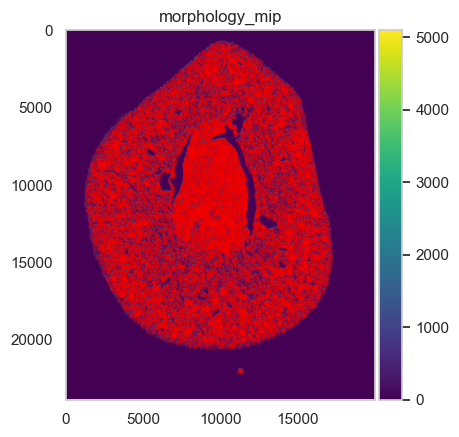

In [13]:
import matplotlib.pyplot as plt
POINTS_KEY = "transcripts"

ds.plot_image(sdata, image_key=IMAGE_KEY, cmap="viridis")
ds.extract_spatialdata_scale(sdata, element_name=POINTS_KEY)
ds.plot_downsampled_vector(s=0.01)
plt.show()

## Step 4 — Clustering

In [ ]:
import rapids_singlecell as rsc

rsc.pp.pca(adata, n_comps=50)
rsc.pp.neighbors(adata, n_neighbors=15)
rsc.tl.leiden(adata, resolution=1)

In [ ]:
adata.write_h5ad(f"{STORE}/mouse_kidney_cls.h5ad")

## Step 5 — Agentic annotation (external step)

Cluster → cell-type identity is assigned by the **annotate-mode** skill (LLM + Cell-Ontology
KG), which runs *outside* this notebook and writes h5ad file with `obs['celltype_annotation']`.

/annotate-mode Annotate the h5ad file below using the annotate-expert agent.

- input : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/ssaft/mouse_kidney_cls.h5ad
- out   : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/ssaft
- tissue : mouse, kidney
- cluster column : leiden 
- virtual env : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv
- note : use 5090 GPU on device '1'

/tmp/ipykernel_2029014/474328934.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(anno, color="cellman_annotation", spot_size=10)


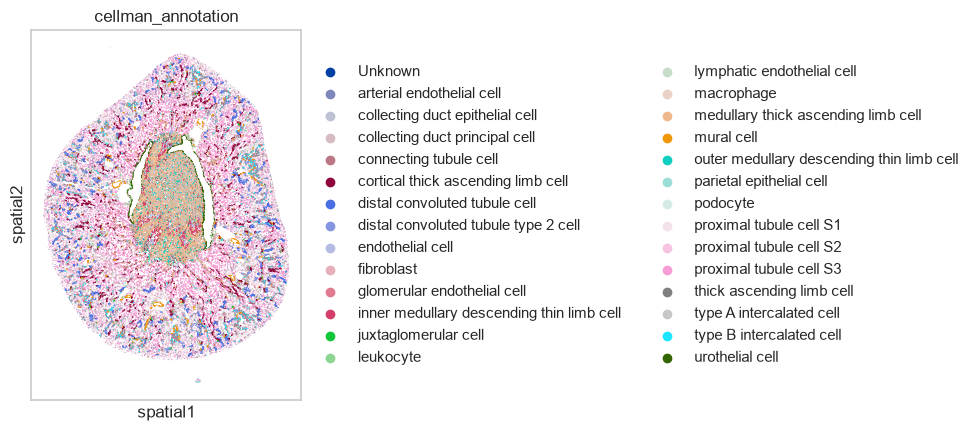

In [3]:
import scanpy as sc

ANNO = f"{STORE}/annotation_out/mouse_kidney_cls_annotated.h5ad" 
if Path(ANNO).exists():
    anno = sc.read_h5ad(ANNO)
    sc.pl.spatial(anno, color="cellman_annotation", spot_size=10)
else:
    anno = None
    print("annotation not found yet — run annotate-mode to produce:", ANNO)

## Step 6 — `map_celltypes`

`map_celltypes` picks the **GPU** implementation automatically when a CUDA device is available (`force_cpu=True` forces CPU). `method='corr'` is the default for transcript data.

In [6]:
sdata = analysis.map_celltypes(sdata, method="corr", gpu_device=DEVICE, h5ad=ANNO)
sdata

[map_celltypes] building centroids from mouse_kidney_cls_annotated.h5ad: 28 celltypes, 258583 vectors
    id=  0  juxtaglomerular cell              [celltype]  (1025 vectors)
    id=  1  mural cell                        [celltype]  (6375 vectors)
    id=  2  fibroblast                        [celltype]  (9711 vectors)
    id=  3  arterial endothelial cell         [celltype]  (6624 vectors)
    id=  4  endothelial cell                  [celltype]  (13011 vectors)
    id=  5  glomerular endothelial cell       [celltype]  (8074 vectors)
    id=  6  lymphatic endothelial cell        [celltype]  (1519 vectors)
    id=  7  leukocyte                         [celltype]  (3524 vectors)
    id=  8  macrophage                        [celltype]  (5410 vectors)
    id=  9  cortical thick ascending limb cell  [celltype]  (15928 vectors)
    id= 10  collecting duct epithelial cell   [celltype]  (826 vectors)
    id= 11  collecting duct principal cell    [celltype]  (9349 vectors)
    id= 12  type A 

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=41, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)


[map_celltypes] wrote cluster_labels (258583,) + centroids (28, 541) + celltype_names (28) + colors (normalized_vectors untouched)
[map_celltypes] wrote /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/ssaft/celltype_index.csv
map_celltypes: GPU path (cuda:1)


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=23, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
KDE chunk 122/122: 100%|██████████| 3/3 [00:00<00:00,  5.40it/s]


[map_celltypes] tables['cellman_downsampled'] (258583, 541) 28 celltypes


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
│     └── 'morphology_mip': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
│     └── 'nucleus_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
└── Tables
      ├── 'cellman_downsampled': AnnData (258583, 541)
      └── 'table': AnnDa

In [7]:
sdata = analysis.filter_celltypemaps(sdata, min_r=0.6)
sdata

[write_celltype_map] labels['cellman_celltype_map'] (5075, 4242) + images['cellman_celltype_map_rgb'] (28 celltypes) @ 1.0µm/px, origin=(0.7,1.2)


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr
├── Images
│     ├── 'cellman_celltype_map_rgb': DataArray[cyx] (3, 5075, 4242)
│     ├── 'morphology_focus': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
│     └── 'morphology_mip': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
│     ├── 'cellman_celltype_map': DataArray[yx] (5075, 4242)
│     └── 'nucleus_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
│     └── 'nucleus_boundaries': Geo

In [9]:
ds.extract_spatialdata_scale(sdata)

(np.float64(4.705882352941177), np.float64(4.705882352941177))

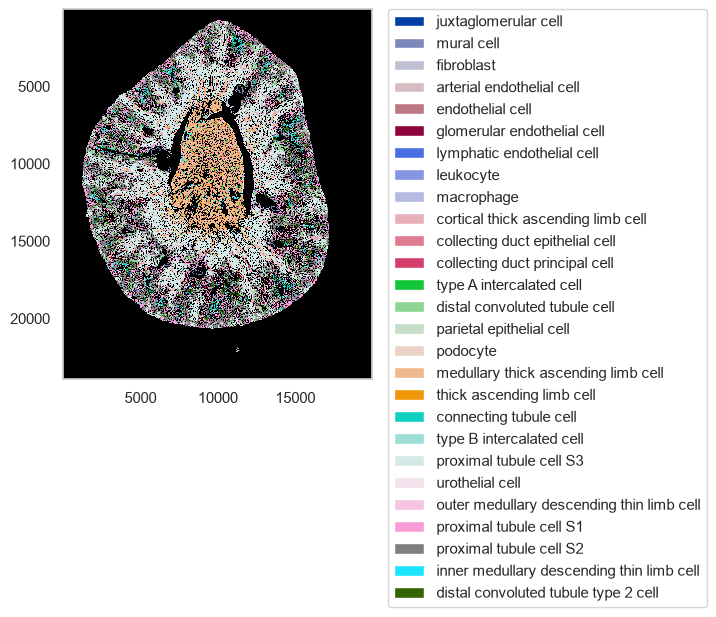

In [10]:
ds.plot_celltypes_map(show_annotation=True)